# SARS-CoV-2 in animals: mink, white-tailed deer and cats

---

### Why this virus

Mpox had no host contrast. SARS-CoV-2 does: it jumped from humans into several animals, with very different outcomes. This notebook uses the mentor's keywords: **host, transmission, sporadic, sustained**.

| Host | Genomes | Expected role (from the literature, to be checked here) |
|---|---|---|
| **Cats** | 112 | **Dead-end spillover**: pet cats infected by owners; little cat-to-cat spread |
| **Mink** | 1,442 | **Outbreaks on farms that were ended** by culling |
| **White-tailed deer** | 308 | **Sustained circulation candidate**: wild animals, not culled |

### The data

GISAID hCoV-19, filters *Complete*, *High coverage*, *Collection date complete*; one search per host, downloaded as "Input for the Augur pipeline" (metadata plus FASTA). Mink combines the labels *Neovison vison* (1,219) and *Neogale vison* (223); deer combines *Odocoileus virginianus* (306) and *White-tailed deer* (2). Merged by `scripts/merge_gisaid_augur.py`, labelled by Nextclade (`nextstrain/sars-cov-2/wuhan-hu-1/orfs`), clustered by `scripts/run_sars2_hosts.py`.

### What is asked

1. Does **composition** (GC, CpG) differ by host?
2. How many separate **transmission clusters** does each host have, and how large and long-lived? (the sporadic-versus-sustained read-out)
3. Does the **mutation spectrum** differ by host?

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath("../../src"))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

os.chdir(os.path.abspath("../.."))
pd.set_option("display.width", 130)
plt.rcParams.update({"figure.dpi": 110, "font.size": 9,
                     "axes.spines.top": False, "axes.spines.right": False})
COL = {"mink": "#6A3D9A", "deer": "#1B9E77", "cat": "#E08214", "baseline": "#777777"}


## 1. The data

In [2]:
f = pd.read_csv("data/processed/Cov_19/Cov_19_features.tsv", sep="\t", dtype={"date": str})
f["hostg"] = f.host.map(lambda h: "mink" if h in ("Neovison vison", "Neogale vison") else "deer" if h in ("Odocoileus virginianus", "White-tailed deer") else "cat")
f["year"] = f.date.str[:4].astype(int)
t = f.groupby("hostg").agg(genomes=("year", "size"), first_year=("year", "min"), last_year=("year", "max"),
                           countries=("country", "nunique"), lineages=("pangolin_lineage", "nunique"))
t.loc[["cat", "mink", "deer"]]

,genomes,first_year,last_year,countries,lineages
hostg,,,,,
cat,2395,2020,2022,19,49
mink,1442,2020,2023,9,32
deer,308,2020,2024,2,33


In [3]:
for h in ["mink", "deer", "cat"]:
    x = f[f.hostg == h]
    print(h, "| countries:", x.country.value_counts().head(5).to_dict())
    print("     lineages:", x.pangolin_lineage.value_counts().head(6).to_dict())

mink | countries: {'Netherlands': 478, 'USA': 442, 'Denmark': 345, 'Latvia': 113, 'Poland': 29}
     lineages: {'B.1.1.298': 320, 'B.1.8': 290, 'B.1': 236, 'AY.39': 223, 'B.1.177.60': 105, 'B.1.22': 94}
deer | countries: {'USA': 303, 'Canada': 5}
     lineages: {'AY.103': 55, 'B.1.1.7': 45, 'B.1.2': 40, 'AY.39': 19, 'B.1.311': 17, 'AY.25': 16}
cat | countries: {'USA': 1613, 'Denmark': 625, 'Netherlands': 96, 'South Korea': 24, 'Switzerland': 9}
     lineages: {'B.1.1.298': 625, 'B.1.2': 509, 'AY.103': 507, 'B.1': 504, 'B.1.8': 96, 'B.1.1.7': 76}


**Reading it.** All genomes are complete (29.7-29.9 kb) with full dates. Mink come mostly from the Netherlands, the USA, Denmark and Latvia (2020-2023); deer almost entirely from the USA (303 of 308; 2020-2024) with 33 different lineages; cats from 18 countries (2020-2021). No host is a single lineage except the 223 *Neogale* mink, all lineage AY.39 from one US group in 2022.

## 2. Composition by host

In [4]:
f.groupby("hostg")[["gc_content", "oe_CG", "oe_TA", "oe_TC"]].mean().round(4).loc[["cat", "mink", "deer"]]

,gc_content,oe_CG,oe_TA,oe_TC
hostg,,,,
cat,0.3797,0.4075,0.8290,0.8001
mink,0.3797,0.4067,0.8293,0.8001
deer,0.3792,0.4073,0.8301,0.7982


**Reading it.** **No difference.** GC is 0.379-0.380 and CpG O/E 0.406-0.407 in every host (a strongly CpG-suppressed virus, as expected for a coronavirus). Composition does not mark the host here either, the same result as RSV, Nipah and mpox.

## 3. Clusters: how many separate chains, how big, how long

Genomes differing by **3 or fewer substitutions** are joined into one cluster (clustered inside each host, gaps ignored). A cluster of 1-2 genomes looks sporadic; 10 or more spanning at least half a year looks sustained. Distance thresholds 2 and 5 give the same picture.

In [5]:
sm = pd.read_csv("results/sars2_host_summary.tsv", sep="\t")
s = sm[(sm.scope == "within host") & (sm["T"] == 3)].set_index("host").loc[["cat", "mink", "deer"]]
s[["genomes", "clusters", "singletons", "largest_cluster", "sporadic", "intermediate", "sustained", "max_span_years"]].round(2)

,genomes,clusters,singletons,largest_cluster,sporadic,intermediate,sustained,max_span_years
host,,,,,,,,
cat,112,102,94,3,100,2,0,0.17
mink,1442,140,71,311,95,42,3,1.17
deer,308,253,220,9,242,11,0,0.09


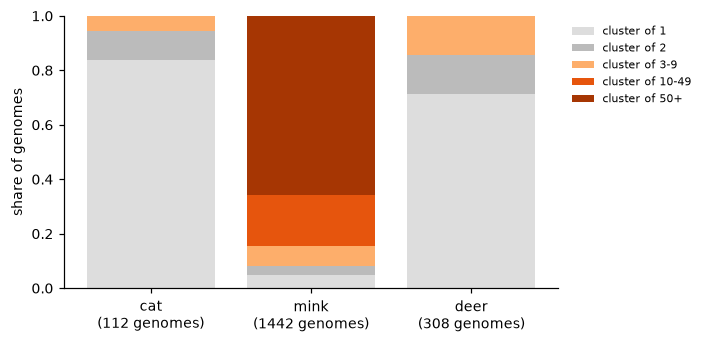

size_bin,1,2,3-9,10-49,50+
scope_host,,,,,
cat,94,12,6,0,0
mink,71,48,107,270,946
deer,220,44,44,0,0


In [6]:
g = pd.read_csv("data/processed/Cov_19/Cov_19_clusters.tsv", sep="\t", low_memory=False)
g["size_bin"] = pd.cut(g["size"], [0, 1, 2, 9, 49, 10**6], labels=["1", "2", "3-9", "10-49", "50+"])
tb = pd.crosstab(g.scope_host, g.size_bin).loc[["cat", "mink", "deer"]]
fig, ax = plt.subplots(figsize=(6.5, 3.2))
bottom = np.zeros(3)
cols = ["#dddddd", "#bbbbbb", "#fdae6b", "#e6550d", "#a63603"]
for c, col in zip(tb.columns, cols):
    v = tb[c].values / tb.sum(axis=1).values
    ax.bar(range(3), v, bottom=bottom, color=col, label=f"cluster of {c}")
    bottom += v
ax.set_xticks(range(3)); ax.set_xticklabels([f"{h}\n({n} genomes)" for h, n in zip(tb.index, tb.sum(axis=1))])
ax.set_ylabel("share of genomes"); ax.legend(frameon=False, fontsize=7, bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout(); fig.savefig("results/figures/sars2_cluster_sizes.png", dpi=200, bbox_inches="tight"); plt.show()
tb

In [7]:
c = pd.read_csv("results/sars2_host_clusters.tsv", sep="\t")
c[c["class"] == "sustained"][["scope_host", "size", "span_years", "countries", "lineages"]].round(2)

,scope_host,size,span_years,countries,lineages
368,mink,28,1.17,1,B.1
370,mink,63,1.06,1,B.1
434,mink,14,1.00,1,B.1


**Reading it.**

- **Cats: 112 genomes, 102 clusters, 94 singletons, the largest cluster has 3 genomes.** Pure dead-end spillover, as expected.
- **Mink: 140 clusters, but 84% of genomes sit in clusters of 10 or more**, up to **311 genomes** (one cluster of lineages B.1.1 and B.1.1.298 in a single country). Only **3 clusters qualify as sustained** (14, 28 and 63 genomes, all lineage B.1, spanning up to 1.2 years); the big clusters are mostly **intense, short outbreaks** (spans of 0.04-0.4 years).
- **Deer: 308 genomes, 253 clusters, 220 singletons, the largest has 9, none sustained.** This is the opposite of what one might guess from "sustained circulation". It reflects the **sampling**, not the transmission: 308 genomes over 5 years and 33 lineages from across the USA are a sparse sample of a large, diverse deer population, so few genomes have a near-identical relative.

**This is why cluster size is a weak marker here.** In mpox, clusters separated the groups. For SARS-CoV-2 animals, cluster size mostly reflects **how intensely each farm or region was sampled** (hundreds of genomes from a few mink farms; a sparse scatter from deer), so it cannot tell sporadic from sustained by itself.

## 4. The mutation spectrum by host

For each genome, the substitutions it carries relative to its nearest neighbour in the Nextclade reference tree (**recent mutations**; genomes with at most 1% unreadable bases and at most 30 recent mutations). The **baseline** is the spectrum along all branches of the same reference tree, which is mostly human SARS-CoV-2.

In [8]:
sp = pd.read_csv("results/sars2_spectrum_by_host.tsv", sep="\t")
base = pd.read_csv("results/sars2_baseline_spectrum.tsv", sep="\t").set_index("type").share
types = ["C>T", "G>T", "A>G", "T>C", "G>A"]
rows = {}
for h in ["cat", "mink", "deer"]:
    x = sp[sp.host == h]; w = x["recent mutations"]
    rows[h] = {t: (x[t] * w).sum() / w.sum() for t in types}
rows["baseline (reference tree)"] = {t: base[t] for t in types}
tab = pd.DataFrame(rows).T
tab["recent mutations"] = [int(sp[sp.host == h]["recent mutations"].sum()) for h in ["cat", "mink", "deer"]] + [int(pd.read_csv("results/sars2_baseline_spectrum.tsv", sep="\t").mutations[0])]
tab.round(3)

,C>T,G>T,A>G,T>C,G>A,recent mutations
cat,0.424,0.197,0.081,0.085,0.075,826
mink,0.394,0.164,0.079,0.086,0.130,16501
deer,0.633,0.101,0.072,0.068,0.057,3704
baseline (reference tree),0.374,0.072,0.111,0.108,0.109,34715


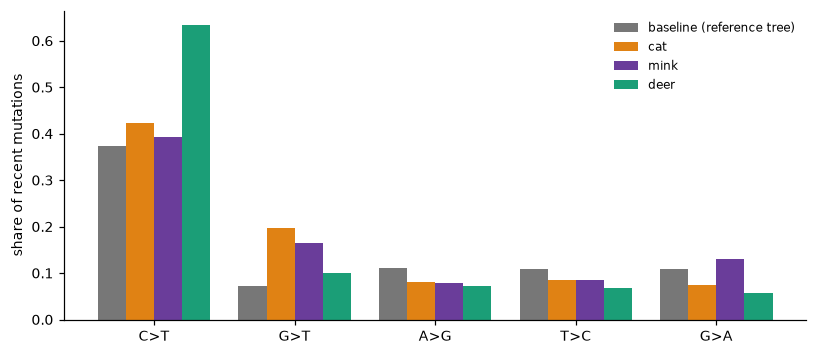

In [9]:
fig, ax = plt.subplots(figsize=(7.5, 3.3))
w = .2
for i, (h, c) in enumerate([("baseline (reference tree)", COL["baseline"]), ("cat", COL["cat"]), ("mink", COL["mink"]), ("deer", COL["deer"])]):
    ax.bar(np.arange(len(types)) + (i - 1.5) * w, tab.loc[h, types], w, color=c, label=h)
ax.set_xticks(range(len(types))); ax.set_xticklabels(types); ax.set_ylabel("share of recent mutations")
ax.legend(frameon=False, fontsize=8)
plt.tight_layout(); fig.savefig("results/figures/sars2_spectrum.png", dpi=200, bbox_inches="tight"); plt.show()

In [10]:
lab = pd.read_csv("results/sars2_spectrum_by_lab.tsv", sep="\t")
lab.sort_values(["host", "C>T"]).round(2)

,host,lab,genomes,recent mutations,C>T,G>T,A>G,T>C,G>A
1,cat,"Emerging Infectious Disease lab, Foreign Anima...",24,267,0.35,0.27,0.07,0.07,0.06
0,cat,"Diagnostic Virology Laboratory, National Veter...",40,268,0.45,0.19,0.06,0.10,0.10
4,deer,Pennsylvania State Laboratory,73,834,0.60,0.11,0.08,0.03,0.08
2,deer,"Diagnostic Virology Laboratory, National Veter...",27,487,0.65,0.12,0.06,0.06,0.05
3,deer,"Diagnostic Virology Laboratory, National Veter...",122,2027,0.65,0.09,0.07,0.09,0.05
11,mink,Latvian Biomedical Research and Study Centre,113,2084,0.20,0.23,0.11,0.06,0.13
14,mink,"The Ohio State University, Department of Veter...",223,4558,0.36,0.16,0.11,0.16,0.12
13,mink,"Pathogen Discovery, Respiratory Viruses Branch...",91,1420,0.41,0.10,0.09,0.07,0.11
10,mink,Laboratory of Recombinant Vaccines,10,172,0.42,0.34,0.01,0.06,0.06
8,mink,Erasmus Medical Center,195,1887,0.42,0.16,0.07,0.02,0.19


In [11]:
pd.read_csv("results/sars2_spectrum_recurrent.tsv", sep="\t").round(3)

,host,recurrent mutations,C>T,G>T,A>G,T>C,G>A
0,cat,125,0.448,0.208,0.080,0.096,0.072
1,deer,626,0.631,0.099,0.080,0.064,0.062
2,mink,652,0.388,0.183,0.072,0.089,0.126


**Reading it.**

- **Deer carry a strongly C>T-rich spectrum: about 0.63 of recent mutations against 0.37 in the reference tree.** G>T is 0.10, close to the baseline 0.07 (mink 0.16 and cats 0.20 are higher); A>G, T>C and G>A are all lower in deer, which is what a larger C>T share does to the rest.
- **It is not one lab's artefact.** All three deer-submitting labs give 0.60-0.65. And **recurrent mutations** (seen in two or more genomes, so not sequencing noise) show the same 0.63. Sequencing damage mostly produces private, one-off changes, which this check removes.
- **Mink and cats do not share it**: mink 0.39-0.40 (recurrent 0.39), cats 0.42. Mink also vary a lot by lab (0.20-0.61), most likely because the labs sequenced different lineages and farms.
- **Mink and cats show more G>T** (0.16-0.20; baseline 0.07). G>T and C>A are the typical signature of **oxidative damage in the sample**, so this may be a laboratory effect, not biology. This is a flag, not a finding.

**Literature (not verified in detail here):** deer-specific C>T changes have been reported in Pennsylvania deer genomes in a preprint, and a highly divergent deer lineage (B.1.641) with many mammal-linked mutations in an Ontario study (Pickering et al., *Nature Microbiology* 2022). Both point the same way as the spectrum seen here.

## 5. What this means for the mentor's keywords

| Keyword | Answer |
|---|---|
| **Host** | Real contrast: cats, mink and deer. |
| **Sporadic versus sustained** | **Cluster size cannot separate them** here because it follows sampling effort. Cats look sporadic (largest cluster 3); mink have intense short outbreaks and 3 sustained-looking clusters; deer have none, which is a sampling effect. |
| **Transmission marker** | **Candidate: a C>T-rich mutation spectrum in deer** (0.63 against 0.37), consistent across three labs and in recurrent mutations. Composition (GC, CpG) shows nothing. |

This repeats the mpox lesson: **the mutation spectrum, not composition, is the informative feature.** The mpox marker was APOBEC3 (C>T after T); here the C>T excess in deer may be the same kind of host-enzyme signature, but that is a hypothesis.

### Limits

- **No human comparison yet.** The baseline is the reference tree, which has different lineages and sampling from the animal data. A fair test needs **human genomes of the same lineages, countries and months** (next step). **Done in notebook 02** (`SARS2/02_human_comparison.ipynb`): the deer C>T excess holds within three matched lineages, so it is not a lineage-sampling artefact.
- **"Recent mutations" depend on the Nextclade tree**, and singletons carry more noise.
- **Deer spectrum could reflect the lineages sampled**, not the host: deer genomes come from a few lineages (AY.103, B.1.1.7 and B.1.2 are the most common here). A human comparison within the same lineages answers this.
- **Sampling** drives cluster size; counts of genomes are not counts of spillovers.

### Next steps

1. ~~Pull a human comparison set and test the spectrum within lineage, deer against human.~~ **Done — see notebook 02.** Result: the deer C>T excess holds in all three matched lineages; mink shows no consistent direction.
2. **Test the deer C>T excess against known effects**: positions (silent versus not), and APOBEC-type context (a C after a U), as in the mpox analysis.
3. **Build our own tree** (IQ-TREE) to count independent spillover events per host, instead of relying on cluster size.